## Stage 2: Joint LSTM for Intent Classification and Slot Filling

### Introduction

This notebook implements a Joint LSTM model for Intent Classification and BIO-based slot filling using the en-US dataset.

The model is trained for both tasks and evaluated using:
- Intent classification Accuracy
- Exact-span Slot Micro-F1

The best model checkpoint is selected using the combined validation score, calculated as the average of intent accuracy and slot micro-F1.

### Import and Configuration

This section imports the required libraries and defines the configuration settings used throught this project.

In [123]:
import json
import random
import re
import time

from pathlib import Path
# Dataset path relative to the notebook's working directory
DATA_PATH = (
    Path("amazon-massive-dataset-1.0")
    / "1.0"
    / "data"
    / "en-US.jsonl"
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import (
    pad_sequence,
    pack_padded_sequence,
    pad_packed_sequence
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Random seed set to:", SEED)

Random seed set to: 42


### Data Loading

This section loads the en-US dataset using its training, validation and test splits.

Dataset contains:
- 11, 514 training examples
- 2, 033 validation examples
- 2, 974 test examples

In [124]:
# Verify that the dataset exists
assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH.resolve()}"

# Load MASSIVE en-US dataset
df = pd.read_json(DATA_PATH, lines=True)

# verify official dataset partition sizes
value_counts = df["partition"].value_counts()
print(value_counts)


train_counts = value_counts["train"]
dev_counts = value_counts["dev"]
test_counts = value_counts["test"]

assert train_counts == 11514, f"Expected 11514, but got {train_counts}"
assert dev_counts == 2033, f"Expected 2033, but got {dev_counts}"
assert test_counts == 2974, f"Expected 2974, but got {test_counts}"

print("\nMissing values:")
print(df.isnull().sum())

df.head()

partition
train    11514
test      2974
dev       2033
Name: count, dtype: int64

Missing values:
id           0
locale       0
partition    0
scenario     0
intent       0
utt          0
annot_utt    0
worker_id    0
dtype: int64


,id,locale,partition,scenario,intent,utt,annot_utt,worker_id
0,0,en-US,test,alarm,alarm_set,wake me up at five am this week,wake me up at [time : five am] [date : this week],1
1,1,en-US,train,alarm,alarm_set,wake me up at nine am on friday,wake me up at [time : nine am] on [date : friday],1
2,2,en-US,train,alarm,alarm_set,set an alarm for two hours from now,set an alarm for [time : two hours from now],1
3,3,en-US,test,audio,audio_volume_mute,quiet,quiet,1
4,4,en-US,train,audio,audio_volume_mute,olly quiet,olly quiet,1


In [125]:
# Split the dataset using the official partitions
train_df = df[df["partition"] == "train"].copy()
dev_df = df[df["partition"] == "dev"].copy()
test_df = df[df["partition"] == "test"].copy()

# Verify split sizes
print("Training examples:", len(train_df))
print("Development examples:", len(dev_df))
print("Testing examples:", len(test_df))

Training examples: 11514
Development examples: 2033
Testing examples: 2974


### Data Preprocessing

This section preapres the utterances and annotations for the Joint LSTM model.

These steps include tokenisation, extraction of BIO slot lables, vocab construction, numerical encoding and sequence padding.

In [6]:
# Tokenize the utt by splitting into words based on whitespace
train_df["tokens"] = train_df["utt"].apply(lambda utt: utt.split())

# Display tokenisation results
train_df[["utt", "tokens"]].head()

,utt,tokens
1,wake me up at nine am on friday,"[wake, me, up, at, nine, am, on, friday]"
2,set an alarm for two hours from now,"[set, an, alarm, for, two, hours, from, now]"
4,olly quiet,"[olly, quiet]"
5,stop,[stop]
6,olly pause for ten seconds,"[olly, pause, for, ten, seconds]"


In [7]:
all_words = []

for sentence in train_df["tokens"]:
    for word in sentence:
        all_words.append(word)
# remove duplicate        
unique_words = set(all_words) 
        
print("Total tokens (including repeated words):", len(all_words))
print("Unique words (distinct words only):", len(unique_words))

Total tokens (including repeated words): 79732
Unique words (distinct words only): 5302


In [8]:
sorted_words = sorted(unique_words)
print(sorted_words[:10])
print(len(sorted_words))

['&', '<empty>', 'a', 'a.', 'aa', 'aapa', 'aaron', 'abdul', 'abita', 'able']
5302


In [9]:
word2idx = {
    "<PAD>": 0,
    "<UNK>": 1
}
#assign ID for every word
for idx, word in enumerate(sorted_words, start = 2):
    word2idx[word] = idx
    
print("Vocabulary size: ", len(word2idx))
print("PAD index:", word2idx["<PAD>"])
print("UNK index:", word2idx["<UNK>"])

Vocabulary size:  5304
PAD index: 0
UNK index: 1


In [10]:
#convert each sentence into ID
train_df["token_ids"] = train_df["tokens"].apply(
    lambda tokens: [word2idx.get(word, 1) for word in tokens]
)
train_df[["utt", "tokens", "token_ids"]].head()

,utt,tokens,token_ids
1,wake me up at nine am on friday,"[wake, me, up, at, nine, am, on, friday]","[5077, 2875, 4987, 278, 3162, 139, 3266, 1815]"
2,set an alarm for two hours from now,"[set, an, alarm, for, two, hours, from, now]","[4194, 161, 100, 1761, 4949, 2165, 1824, 3199]"
4,olly quiet,"[olly, quiet]","[3263, 3716]"
5,stop,[stop],[4512]
6,olly pause for ten seconds,"[olly, pause, for, ten, seconds]","[3263, 3397, 1761, 4714, 4150]"


In [11]:
#checks if number of words in tokens = number of IDs in token_ids for every utt
checks = [
    len(tokens) == len(ids)
     for tokens, ids in zip(train_df["tokens"], train_df["token_ids"])
]

print("All lengths match: ", all(checks))
print("Number of checks: ", len(checks))
print("Training utterances: ", len(train_df))

All lengths match:  True
Number of checks:  11514
Training utterances:  11514


In [12]:
train_df[["utt", "annot_utt", "intent"]].head(15)

,utt,annot_utt,intent
1,wake me up at nine am on friday,wake me up at [time : nine am] on [date : friday],alarm_set
2,set an alarm for two hours from now,set an alarm for [time : two hours from now],alarm_set
4,olly quiet,olly quiet,audio_volume_mute
5,stop,stop,audio_volume_mute
6,olly pause for ten seconds,olly pause for [time : ten seconds],audio_volume_mute
7,pause for ten seconds,pause for [time : ten seconds],audio_volume_mute
9,make the lighting bit more warm here,make the lighting bit more [color_type : warm]...,iot_hue_lightchange
10,please set the lighting suitable for reading,please set the lighting [color_type : suitable...,iot_hue_lightchange
12,time to sleep,time to sleep,iot_hue_lightoff
13,time to sleep olly,time to sleep olly,iot_hue_lightoff


In [13]:
import re

def process_text(text):

    matches = re.finditer(r"\[([^:\]]+)\s:\s([^\]]+)\]", text)

    tokens = []
    bio_labels = []
    cursor = 0

    for match in matches:
        ordinary_text = text[cursor:match.start()]

        for word in ordinary_text.split():
            tokens.append(word)
            bio_labels.append("O")

        slot_type = match.group(1)
        slot_value = match.group(2)

        slot_tokens = slot_value.split()

        # Process the slot words here
        for idx, word in enumerate(slot_tokens):
            if idx == 0:
                label = "B-" + slot_type
            else:
                label = "I-" + slot_type

            tokens.append(word)
            bio_labels.append(label)

        cursor = match.end()

    remaining_text = text[cursor:]

    for word in remaining_text.split():
        tokens.append(word)
        bio_labels.append("O")
        
    return tokens, bio_labels

In [14]:
print("Original utterance:")
print(train_df.iloc[0]["utt"])

print("\nAnnotated utterance:")
print(train_df.iloc[0]["annot_utt"])

print("\nExisting tokens:")
print(train_df.iloc[0]["tokens"])

Original utterance:
wake me up at nine am on friday

Annotated utterance:
wake me up at [time : nine am] on [date : friday]

Existing tokens:
['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday']


In [15]:
words, labels = process_text(
    "play [genre : jazz] at [time : noon] please"
)

print("Tokens:", words)
print("BIO labels:", labels)

assert len(words) == len(labels)

Tokens: ['play', 'jazz', 'at', 'noon', 'please']
BIO labels: ['O', 'B-genre', 'O', 'B-time', 'O']


In [16]:
parsed_results = train_df["annot_utt"].apply(process_text)
parsed_tokens = parsed_results.apply(lambda result: result[0])
print(parsed_results.iloc[0])
print(parsed_tokens.iloc[0])
print(train_df["tokens"].iloc[0])

(['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday'], ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date'])
['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday']
['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday']


In [17]:
alignment_checks = [
    original == parsed
    for original, parsed in zip(train_df["tokens"], parsed_tokens)
]

print("Total examples:", len(alignment_checks))
print("Matching examples:", sum(alignment_checks))
print("All matched:", all(alignment_checks))

Total examples: 11514
Matching examples: 11514
All matched: True


In [18]:
parsed_labels = parsed_results.apply(lambda result: result[1])
label_alignment_checks = [
    len(tokens) == len(labels)
    for tokens, labels in zip(train_df["tokens"], parsed_labels)
]

print("Total examples:", len(label_alignment_checks))
print("Matching lengths:", sum(label_alignment_checks))
print("All matched:", all(label_alignment_checks))

Total examples: 11514
Matching lengths: 11514
All matched: True


In [19]:
all_labels = []

for labels in parsed_labels:
    for label in labels:
        all_labels.append(label)

unique_labels = set(all_labels)
sorted_labels = sorted(unique_labels)

print("Total BIO labels:", len(all_labels))
print("Unique BIO labels:", len(unique_labels))
print("Sorted labels:", sorted_labels)

Total BIO labels: 79732
Unique BIO labels: 107
Sorted labels: ['B-alarm_type', 'B-app_name', 'B-artist_name', 'B-audiobook_author', 'B-audiobook_name', 'B-business_name', 'B-business_type', 'B-change_amount', 'B-coffee_type', 'B-color_type', 'B-cooking_type', 'B-currency_name', 'B-date', 'B-definition_word', 'B-device_type', 'B-drink_type', 'B-email_address', 'B-email_folder', 'B-event_name', 'B-food_type', 'B-game_name', 'B-game_type', 'B-general_frequency', 'B-house_place', 'B-ingredient', 'B-joke_type', 'B-list_name', 'B-meal_type', 'B-media_type', 'B-movie_name', 'B-movie_type', 'B-music_album', 'B-music_descriptor', 'B-music_genre', 'B-news_topic', 'B-order_type', 'B-person', 'B-personal_info', 'B-place_name', 'B-player_setting', 'B-playlist_name', 'B-podcast_descriptor', 'B-podcast_name', 'B-radio_name', 'B-relation', 'B-song_name', 'B-sport_type', 'B-time', 'B-time_zone', 'B-timeofday', 'B-transport_agency', 'B-transport_descriptor', 'B-transport_name', 'B-transport_type', 'B-we

In [20]:
slot2idx = {"O": 0}

for label in sorted_labels:
    if label != "O":
        # Assign the next available ID
        slot2idx[label] = len(slot2idx)
print("Number of slot labels:", len(slot2idx))
print("O label ID:", slot2idx["O"])
print("B-time label ID:", slot2idx["B-time"])
print("I-time label ID:", slot2idx["I-time"])

Number of slot labels: 107
O label ID: 0
B-time label ID: 48
I-time label ID: 100


In [21]:
label_ids = parsed_labels.apply(
    lambda labels: [slot2idx[label] for label in labels]
)
print("Original BIO labels:", parsed_labels.iloc[0])
print("Numerical label IDs:", label_ids.iloc[0])
print("Number of examples:", len(label_ids))

Original BIO labels: ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date']
Numerical label IDs: [0, 0, 0, 0, 48, 100, 0, 13]
Number of examples: 11514


In [22]:
checks = [
    len(tokens) == len(labels)
    for tokens, labels in zip(train_df["token_ids"], label_ids)
]

print("Total examples:", len(checks))
print("Matching lengths:", sum(checks))
print("All aligned:", all(checks))

Total examples: 11514
Matching lengths: 11514
All aligned: True


In [23]:
print(train_df["intent"].head())
print("Unique intents:", train_df["intent"].nunique())

1            alarm_set
2            alarm_set
4    audio_volume_mute
5    audio_volume_mute
6    audio_volume_mute
Name: intent, dtype: object
Unique intents: 60


In [24]:
unique_intents = train_df["intent"].unique()
sorted_intents = sorted(unique_intents)

In [25]:
print("Number of intents:", len(sorted_intents))
print("First five intents:", sorted_intents[:5])

Number of intents: 60
First five intents: ['alarm_query', 'alarm_remove', 'alarm_set', 'audio_volume_down', 'audio_volume_mute']


In [26]:
intent2idx = {}

for idx, intent in enumerate(sorted_intents):
    intent2idx[intent] = idx
print("Number of intents:", len(intent2idx))
print("alarm_set ID:", intent2idx["alarm_set"])
print("audio_volume_mute ID:", intent2idx["audio_volume_mute"])

Number of intents: 60
alarm_set ID: 2
audio_volume_mute ID: 4


In [27]:
train_df["intent_id"] = train_df["intent"].apply(
    lambda intent: intent2idx[intent]
)
print(train_df[["intent", "intent_id"]].head())
print("Unique intent IDs:", train_df["intent_id"].nunique())

              intent  intent_id
1          alarm_set          2
2          alarm_set          2
4  audio_volume_mute          4
5  audio_volume_mute          4
6  audio_volume_mute          4
Unique intent IDs: 60


In [28]:
# Preparing for dev and test datasets
dev_df = df[df["partition"] == "dev"].copy()

test_df = df[df["partition"] == "test"].copy()

print("Training examples:", len(train_df))
print("Development examples:", len(dev_df))
print("Test examples:", len(test_df))

Training examples: 11514
Development examples: 2033
Test examples: 2974


In [29]:
dev_df["tokens"] = dev_df["utt"].apply(
    lambda utt: utt.split()
)

test_df["tokens"] = test_df["utt"].apply(
    lambda utt: utt.split()
)

In [30]:
print("Development tokens:", dev_df["tokens"].iloc[0])
print("Test tokens:", test_df["tokens"].iloc[0])

Development tokens: ['turn', 'the', 'lights', 'off', 'please']
Test tokens: ['wake', 'me', 'up', 'at', 'five', 'am', 'this', 'week']


In [31]:
dev_df["token_ids"] = dev_df["tokens"].apply(
    lambda tokens: [word2idx.get(word, 1) for word in tokens]
)

test_df["token_ids"] = test_df["tokens"].apply(
    lambda tokens: [word2idx.get(word, 1) for word in tokens]
)
print(dev_df.columns.tolist())
print(test_df.columns.tolist())

['id', 'locale', 'partition', 'scenario', 'intent', 'utt', 'annot_utt', 'worker_id', 'tokens', 'token_ids']
['id', 'locale', 'partition', 'scenario', 'intent', 'utt', 'annot_utt', 'worker_id', 'tokens', 'token_ids']


In [32]:
dev_checks = [
    len(tokens) == len(ids)
    for tokens, ids in zip(dev_df["tokens"], dev_df["token_ids"])
]

print("Development examples:", len(dev_checks))
print("Matching lengths:", sum(dev_checks))
print("All aligned:", all(dev_checks))

test_checks = [
    len(tokens) == len(ids)
    for tokens, ids in zip(test_df["tokens"], test_df["token_ids"])
]

print("Test examples:", len(test_checks))
print("Matching lengths:", sum(test_checks))
print("All aligned:", all(test_checks))

Development examples: 2033
Matching lengths: 2033
All aligned: True
Test examples: 2974
Matching lengths: 2974
All aligned: True


In [33]:
# Prepare BIO labels for DEV and TEST

dev_parsed_results = dev_df["annot_utt"].apply(process_text)

test_parsed_results = test_df["annot_utt"].apply(process_text)

# Extract BIO labels

dev_parsed_labels = dev_parsed_results.apply(lambda result: result[1])

test_parsed_labels = test_parsed_results.apply(lambda result: result[1])

# Verify parser-token alignment

dev_parsed_tokens = dev_parsed_results.apply(lambda result: result[0])

test_parsed_tokens = test_parsed_results.apply(lambda result: result[0])

#Check token alignment

dev_alignment_checks = [original == parsed
                        for original, parsed in zip(dev_df["tokens"], dev_parsed_tokens)
                       ]
print("Total examples:", len(dev_alignment_checks))
print("Matching examples:", sum(dev_alignment_checks))
print("All matched:", all(dev_alignment_checks))
      
test_alignment_checks = [original == parsed
                        for original, parsed in zip(test_df["tokens"], test_parsed_tokens)
                       ]
print("Total examples:", len(test_alignment_checks))
print("Matching examples:", sum(test_alignment_checks))
print("All matched:", all(test_alignment_checks))

Total examples: 2033
Matching examples: 2033
All matched: True
Total examples: 2974
Matching examples: 2974
All matched: True


In [34]:
# Check for unseen BIO labels for DEV
dev_all_labels = []

for labels in dev_parsed_labels:
    for label in labels:
        dev_all_labels.append(label)

unique_dev_labels = set(dev_all_labels)
sorted_dev_labels = sorted(unique_dev_labels)

print("Total BIO labels:", len(dev_all_labels))
print("Unique BIO labels:", len(unique_dev_labels))
print("Sorted labels:", sorted_dev_labels)

unseen_dev_labels = unique_dev_labels - unique_labels

print("Number of unseen development labels:", len(unseen_dev_labels))
print("Unseen development lables:", unseen_dev_labels)

Total BIO labels: 13962
Unique BIO labels: 97
Sorted labels: ['B-alarm_type', 'B-app_name', 'B-artist_name', 'B-audiobook_author', 'B-audiobook_name', 'B-business_name', 'B-business_type', 'B-change_amount', 'B-coffee_type', 'B-color_type', 'B-cooking_type', 'B-currency_name', 'B-date', 'B-definition_word', 'B-device_type', 'B-drink_type', 'B-email_address', 'B-email_folder', 'B-event_name', 'B-food_type', 'B-game_name', 'B-game_type', 'B-general_frequency', 'B-house_place', 'B-ingredient', 'B-joke_type', 'B-list_name', 'B-meal_type', 'B-media_type', 'B-movie_name', 'B-movie_type', 'B-music_descriptor', 'B-music_genre', 'B-news_topic', 'B-order_type', 'B-person', 'B-personal_info', 'B-place_name', 'B-player_setting', 'B-playlist_name', 'B-podcast_descriptor', 'B-podcast_name', 'B-radio_name', 'B-relation', 'B-song_name', 'B-sport_type', 'B-time', 'B-time_zone', 'B-timeofday', 'B-transport_agency', 'B-transport_name', 'B-transport_type', 'B-weather_descriptor', 'I-alarm_type', 'I-artist

In [35]:
# Check for unseen BIO labels for TEST
test_all_labels = []

for labels in test_parsed_labels:
    for label in labels:
        test_all_labels.append(label)

unique_test_labels = set(test_all_labels)
sorted_test_labels = sorted(unique_test_labels)

print("Total BIO labels:", len(test_all_labels))
print("Unique BIO labels:", len(unique_test_labels))
print("Sorted labels:", sorted_test_labels)

unseen_test_labels = unique_test_labels - unique_labels

print("Number of unseen test labels:", len(unseen_test_labels))
print("Unseen test lables:", unseen_test_labels)

Total BIO labels: 20287
Unique BIO labels: 101
Sorted labels: ['B-alarm_type', 'B-app_name', 'B-artist_name', 'B-audiobook_author', 'B-audiobook_name', 'B-business_name', 'B-business_type', 'B-change_amount', 'B-coffee_type', 'B-color_type', 'B-cooking_type', 'B-currency_name', 'B-date', 'B-definition_word', 'B-device_type', 'B-drink_type', 'B-email_address', 'B-email_folder', 'B-event_name', 'B-food_type', 'B-game_name', 'B-general_frequency', 'B-house_place', 'B-ingredient', 'B-joke_type', 'B-list_name', 'B-meal_type', 'B-media_type', 'B-movie_name', 'B-movie_type', 'B-music_album', 'B-music_descriptor', 'B-music_genre', 'B-news_topic', 'B-order_type', 'B-person', 'B-personal_info', 'B-place_name', 'B-player_setting', 'B-playlist_name', 'B-podcast_descriptor', 'B-podcast_name', 'B-radio_name', 'B-relation', 'B-song_name', 'B-time', 'B-time_zone', 'B-timeofday', 'B-transport_agency', 'B-transport_descriptor', 'B-transport_name', 'B-transport_type', 'B-weather_descriptor', 'I-alarm_typ

In [36]:
print("B-transport_type in training:", "B-transport_type" in unique_labels)
print("I-transport_type in training:", "I-transport_type" in unique_labels)

B-transport_type in training: True
I-transport_type in training: False


In [37]:
slot_types = set()

for label in unique_labels:
    if label != "O":
        slot_type = label.split("-")[1]
        slot_types.add(slot_type)
        
print("Number of unique slot types:", len(slot_types))
print("Slot types:", sorted(slot_types))

Number of unique slot types: 55
Slot types: ['alarm_type', 'app_name', 'artist_name', 'audiobook_author', 'audiobook_name', 'business_name', 'business_type', 'change_amount', 'coffee_type', 'color_type', 'cooking_type', 'currency_name', 'date', 'definition_word', 'device_type', 'drink_type', 'email_address', 'email_folder', 'event_name', 'food_type', 'game_name', 'game_type', 'general_frequency', 'house_place', 'ingredient', 'joke_type', 'list_name', 'meal_type', 'media_type', 'movie_name', 'movie_type', 'music_album', 'music_descriptor', 'music_genre', 'news_topic', 'order_type', 'person', 'personal_info', 'place_name', 'player_setting', 'playlist_name', 'podcast_descriptor', 'podcast_name', 'radio_name', 'relation', 'song_name', 'sport_type', 'time', 'time_zone', 'timeofday', 'transport_agency', 'transport_descriptor', 'transport_name', 'transport_type', 'weather_descriptor']


In [38]:
complete_bio_labels = ["O"]

for slot_type in sorted(slot_types):
    complete_bio_labels.append("B-" + slot_type)
    complete_bio_labels.append("I-" + slot_type)
    
print("Total BIO labels:", len(complete_bio_labels))
print("Unique BIO labels:", len(set(complete_bio_labels)))
print("I-transport_type exists: ", "I-transport_type" in complete_bio_labels)

Total BIO labels: 111
Unique BIO labels: 111
I-transport_type exists:  True


In [39]:
# Rebuilding slot2idx with 111 labels

slot2idx = {}

for idx, label in enumerate(complete_bio_labels):
    slot2idx[label] = idx
print("Total BIO labels:", len(slot2idx))
print("O:", slot2idx["O"])
print("B-transport_type:", slot2idx["B-transport_type"])
print("I-transport_type:", slot2idx["I-transport_type"])

Total BIO labels: 111
O: 0
B-transport_type: 107
I-transport_type: 108


In [40]:
# Re-encode training BIO labels
label_ids = parsed_labels.apply(
    lambda labels: [slot2idx[label] for label in labels]
)
print("Original BIO labels:", parsed_labels.iloc[0])
print("Updated label IDs:", label_ids.iloc[0])
print("Matching lengths:", len(parsed_labels.iloc[0]) == len(label_ids.iloc[0]))


Original BIO labels: ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date']
Updated label IDs: [0, 0, 0, 0, 95, 96, 0, 25]
Matching lengths: True


In [41]:
dev_label_ids = dev_parsed_labels.apply(
    lambda labels: [slot2idx[label] for label in labels]
)

print("Original:", dev_parsed_labels.iloc[0])
print("Encoded:", dev_label_ids.iloc[0])
print("Matching lengths:", len(dev_parsed_labels.iloc[0]) == len(dev_label_ids.iloc[0]))

Original: ['O', 'O', 'O', 'O', 'O']
Encoded: [0, 0, 0, 0, 0]
Matching lengths: True


In [42]:
test_label_ids = test_parsed_labels.apply(
    lambda labels: [slot2idx[label] for label in labels]
)

print("Original:", test_parsed_labels.iloc[0])
print("Encoded:", test_label_ids.iloc[0])
print("Matching lengths:", len(test_parsed_labels.iloc[0]) == len(test_label_ids.iloc[0]))

Original: ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'B-date', 'I-date']
Encoded: [0, 0, 0, 0, 95, 96, 25, 26]
Matching lengths: True


In [43]:
#alignment

train_alignment = all(
    len(tokens) == len(labels)
    for tokens, labels in zip(train_df["tokens"], label_ids)
)


dev_alignment = all(
    len(tokens) == len(labels)
    for tokens, labels in zip(dev_df["tokens"], dev_label_ids)
)

test_alignment = all(
    len(tokens) == len(labels)
    for tokens, labels in zip(test_df["tokens"], test_label_ids)
)
print("training alignment:", train_alignment)
print("dev alignment:", dev_alignment)
print("test alignment:", test_alignment)

print(len(train_df), len(label_ids))
print(len(dev_df), len(dev_label_ids))
print(len(test_df), len(test_label_ids))

training alignment: True
dev alignment: True
test alignment: True
11514 11514
2033 2033
2974 2974


In [44]:
# Check unseen dev intents

train_intents = set(train_df["intent"])
dev_intents = set(dev_df["intent"])

unseen_dev_intents = dev_intents - train_intents

print("Unseen development intents:", unseen_dev_intents)
print("Number of unseen intents:", len(unseen_dev_intents))

# Check unseen test intents
test_intents = set(test_df["intent"])

unseen_test_intents = test_intents - train_intents

print("Unseen test intents:", unseen_test_intents)
print("Number of unseen test intents:", len(unseen_test_intents))

Unseen development intents: set()
Number of unseen intents: 0
Unseen test intents: set()
Number of unseen test intents: 0


In [45]:
# Encode dev and test intents
dev_df["intent_id"] = dev_df["intent"].apply(
    lambda intent: intent2idx[intent]
)

test_df["intent_id"] = test_df["intent"].apply(
    lambda intent: intent2idx[intent]
)

print("Training:")
print(train_df[["intent", "intent_id"]].head())

print("\nDevelopment:")
print(dev_df[["intent", "intent_id"]].head())

print("\nTest:")
print(test_df[["intent", "intent_id"]].head())

Training:
              intent  intent_id
1          alarm_set          2
2          alarm_set          2
4  audio_volume_mute          4
5  audio_volume_mute          4
6  audio_volume_mute          4

Development:
              intent  intent_id
11  iot_hue_lightoff         25
17  iot_hue_lightdim         24
24  iot_hue_lightdim         24
26      iot_cleaning         21
30      iot_cleaning         21

Test:
                 intent  intent_id
0             alarm_set          2
3     audio_volume_mute          4
8   iot_hue_lightchange         23
14      iot_hue_lighton         26
19     iot_hue_lightoff         25


In [46]:
print("Training alignment:", train_alignment)
print("Development alignment:", dev_alignment)
print("Test alignment:", test_alignment)

print("Training intent IDs:", len(train_df["intent_id"]))
print("Development intent IDs:", len(dev_df["intent_id"]))
print("Test intent IDs:", len(test_df["intent_id"]))

Training alignment: True
Development alignment: True
Test alignment: True
Training intent IDs: 11514
Development intent IDs: 2033
Test intent IDs: 2974


In [47]:
train_tokens = train_df["token_ids"].tolist()
train_bio_labels = label_ids.tolist()
train_intents = train_df["intent_id"].tolist()
print(len(train_tokens))
print(len(train_bio_labels))
print(len(train_intents))

11514
11514
11514


In [48]:
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Random seed set to:", SEED)

Random seed set to: 42


#### Using PyTorch Dataset to group tokens, bio labels and intent labels together so that model can retrieve one TRAINING example at a time.

In [49]:
import torch
from torch.utils.data import Dataset

class ExampleDataset(Dataset):
    def __init__(self, tokens, labels, intents):
        self.tokens = tokens
        self.labels = labels
        self.intents = intents
        
        assert len(tokens) == len(labels) == len(intents)
        
    def __len__(self):
        return len(self.tokens)
    
    def __getitem__(self, idx):
        return {
            "token_ids": torch.tensor(
                self.tokens[idx], dtype=torch.long
            ),
            "slot_labels": torch.tensor(
                self.labels[idx], dtype=torch.long
            ),
            "intent_label": torch.tensor(
                self.intents[idx], dtype=torch.long
            )
        }
train_dataset = ExampleDataset(
    train_tokens,
    train_bio_labels,
    train_intents
)

print("Dataset size:", len(train_dataset))
print("First example:", train_dataset[0])

Dataset size: 11514
First example: {'token_ids': tensor([5077, 2875, 4987,  278, 3162,  139, 3266, 1815]), 'slot_labels': tensor([ 0,  0,  0,  0, 95, 96,  0, 25]), 'intent_label': tensor(2)}


#### Prepare DataLoader

In [50]:
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader

def collate_fn(batch):
    token_ids = [item["token_ids"] for item in batch]
    slot_labels = [item["slot_labels"] for item in batch]
    intent_labels = [item["intent_label"] for item in batch]
    
    lengths = torch.tensor(
        [len(tokens) for tokens in token_ids],
        dtype = torch.long
    )
    
    padded_tokens = pad_sequence(
        token_ids,
        batch_first = True,
        padding_value = 0
    )
    
    padded_slots = pad_sequence(
        slot_labels,
        batch_first = True,
        padding_value = -100
    )
    
    intent_labels = torch.stack(intent_labels)
    
    return{
        "token_ids": padded_tokens,
        "slot_labels": padded_slots,
        "intent_label": intent_labels,
        "lengths": lengths
    }

# group into batches

# Verify the padding token ID
assert word2idx["<PAD>"] == 0

# Create training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size = 32,
    shuffle = True,
    collate_fn = collate_fn
)

# Retrieve one batch
batch = next(iter(train_loader))

print("Token IDs shape:", batch["token_ids"].shape)
print("Slot labels shape:", batch["slot_labels"].shape)
print("Intent labels shape:", batch["intent_label"].shape)
print("Original lengths:", batch["lengths"])

Token IDs shape: torch.Size([32, 12])
Slot labels shape: torch.Size([32, 12])
Intent labels shape: torch.Size([32])
Original lengths: tensor([ 4,  8,  2,  9,  5,  5,  4, 10,  6,  3,  9,  4,  6,  7,  7, 12,  5,  4,
         9,  7,  5,  8,  4,  5,  8, 10,  4,  6,  6,  6,  7,  6])


In [51]:
# Checking if padding is correct

# Inspect the first sentence in the batch
print("Original length:", batch["lengths"][0].item())
print("Token IDs:", batch["token_ids"][0].tolist())
print("Slot labels:", batch["slot_labels"][0].tolist())

# Verify padding across the entire batch
for i, length in enumerate(batch["lengths"]):
    length = length.item()
    
    assert torch.all(batch["token_ids"][i, length:] == 0)
    assert torch.all(batch["slot_labels"][i, length:] == -100)
    
print("All padding checks passed!")

Original length: 4
Token IDs: [4512, 4198, 139, 100, 0, 0, 0, 0, 0, 0, 0, 0]
Slot labels: [0, 95, 96, 0, -100, -100, -100, -100, -100, -100, -100, -100]
All padding checks passed!


#### Create TEST and DEV Dataloader

In [52]:
# Prep dev data
dev_tokens = dev_df["token_ids"].tolist()
dev_bio_labels = dev_label_ids.tolist()
dev_intents = dev_df["intent_id"].tolist()

# Create dev dataset
dev_dataset = ExampleDataset(
    dev_tokens,
    dev_bio_labels,
    dev_intents
)

# Prep dev data
test_tokens = test_df["token_ids"].tolist()
test_bio_labels = test_label_ids.tolist()
test_intents = test_df["intent_id"].tolist()

# Create test dataset
test_dataset = ExampleDataset(
    test_tokens,
    test_bio_labels,
    test_intents
)

# Create dev DataLoader
dev_loader = DataLoader(
    dev_dataset,
    batch_size = 32,
    shuffle = False,
    collate_fn = collate_fn
)

# Create test DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size = 32,
    shuffle = False,
    collate_fn = collate_fn
)

# Verify lengths
print("Validation:")
print(len(dev_tokens), len(dev_bio_labels), len(dev_intents))

print("Test:")
print(len(test_tokens), len(test_bio_labels), len(test_intents))

# Verify dataset sizes
print("Training examples:", len(train_dataset))
print("DEV examples:", len(dev_dataset))
print("TEST examples:", len(test_dataset))

# Verify number of batches
print("Training batches:", len(train_loader))
print("DEV batches:", len(dev_loader))
print("TEST batches:", len(test_loader))

Validation:
2033 2033 2033
Test:
2974 2974 2974
Training examples: 11514
DEV examples: 2033
TEST examples: 2974
Training batches: 360
DEV batches: 64
TEST batches: 93


#### Define embedding layer, just the first component

In [53]:
import torch
import torch.nn as nn
# Model configuration
vocab_size = len(word2idx)
embedding_dim = 100
hidden_dim = 128

# Create embedding layer
embedding = nn.Embedding(
    num_embeddings=vocab_size,
    embedding_dim=embedding_dim,
    padding_idx=0
)

# Test embedding using one batch
batch = next(iter(train_loader))
token_ids = batch["token_ids"]

embedded = embedding(token_ids)

print("Vocabulary size:", vocab_size)
print("Input shape:", token_ids.shape)
print("Embedding output shape:", embedded.shape)

Vocabulary size: 5304
Input shape: torch.Size([32, 20])
Embedding output shape: torch.Size([32, 20, 100])


#### Implementing unidirectional LSTM

In [54]:
# Create a unidirectional LSTM
lstm = nn.LSTM(
    input_size = embedding_dim,
    hidden_size = hidden_dim,
    num_layers = 1,
    batch_first = True,
    bidirectional = False
)

# Pass embedding thru LSTM
lstm_output, (hidden_state, cell_state) = lstm(embedded)

# contains hidden representation at every token position. To use for slot filling
print("LSTM output shape:", lstm_output.shape)
# contains final hidden state for eacch sentence. To use for intent classification
print("Hidden state shape:", hidden_state.shape)
# contains final memory cell state.
print("Cell state shape:", cell_state.shape)

# Implementing classification heads

# number of output classes
num_intents = 60
num_slot_labels = 111
# Intent classification head
intent_classifier = nn.Linear(
    hidden_dim,
    num_intents
)

# Slot filling head
slot_classifier = nn.Linear(
    hidden_dim,
    num_slot_labels
)

# Intent uses the final hidden state
sentence_representation = hidden_state[-1]

intent_logits = intent_classifier(
    sentence_representation
)

# Slot filling uses all LSTM output
slot_logits = slot_classifier(
    lstm_output
)

print("Intent logits shape:", intent_logits.shape)
print("Slot logits shape:", slot_logits.shape)

LSTM output shape: torch.Size([32, 20, 128])
Hidden state shape: torch.Size([1, 32, 128])
Cell state shape: torch.Size([1, 32, 128])
Intent logits shape: torch.Size([32, 60])
Slot logits shape: torch.Size([32, 20, 111])


#### Combining all into one JOINT LSTM model

In [55]:
# Create model architecture

import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

class JointLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim,
                 hidden_dim, num_intents, num_slot_labels):
        super().__init__()
        
        # Embedding layer
        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx = 0
        )
        
        # Shared LSTM encoder
        self.lstm = nn.LSTM(
            input_size = embedding_dim,
            hidden_size = hidden_dim,
            batch_first = True,
            bidirectional = False
        )
        
        # Intent classification head
        self.intent_classifier = nn.Linear(
            hidden_dim,
            num_intents
        )
        
        # Slot filling head
        self.slot_classifier = nn.Linear(
            hidden_dim,
            num_slot_labels
        )
        
    def forward(self, token_ids, lengths):
        # convert token IDs to embeddings
        embedded = self.embedding(token_ids)
            
        # ignore padded positions during LSTM processing
        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first = True,
            enforce_sorted = False
        )
            
        # Process sequence thru LSTM
        packed_output, (hidden_state, cell_state) = self.lstm(packed)
            
        # Restore padded batch shape
        lstm_output, _ = pad_packed_sequence(
            packed_output,
            batch_first = True,
            total_length = token_ids.size(1)
        )
            
        # One prediction per sentence
        sentence_representation = hidden_state[-1]
        intent_logits = self.intent_classifier(
            sentence_representation
        )
            
        # One prediction per token
        slot_logits = self.slot_classifier(lstm_output)
            
        return intent_logits, slot_logits

In [56]:
# Create and test model

model = JointLSTM(
    vocab_size = 5304,
    embedding_dim = 100,
    hidden_dim = 128,
    num_intents = 60,
    num_slot_labels = 111
)

batch = next(iter(train_loader))

intent_logits, slot_logits = model(
    batch["token_ids"],
    batch["lengths"]
)

print("Intent logits:", intent_logits.shape)
print("Slot logits:", slot_logits.shape)

# Count train parameters
num_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", num_parameters)

Intent logits: torch.Size([32, 60])
Slot logits: torch.Size([32, 23, 111])
Trainable parameters: 670219


#### Model can now produce predictions, but has not learnt anything yet. Weights are still randomly initialised. Need to include loss functions

In [57]:
# Define intent classification loss
intent_loss_fn = nn.CrossEntropyLoss()

# Define slot filling loss
slot_loss_fn = nn.CrossEntropyLoss(
    ignore_index = -100 #cos PAD slot labels use -100, so exclude them
)

# Calculate joint loss

# Ground-truth labels
intent_labels = batch["intent_label"]
slot_labels = batch["slot_labels"]

# Calculate intent loss
intent_loss = intent_loss_fn(
    intent_logits,
    intent_labels
)

# Reshape slot logits and labels for CrossEntropyLoss cos it expects dimension in a particular position
slot_loss = slot_loss_fn(
    slot_logits.reshape(-1, num_slot_labels),
    slot_labels.reshape(-1)
)

# Combine both losses
total_loss = intent_loss + slot_loss

print("Intent loss:", intent_loss.item())
print("Slot loss:", slot_loss.item())
print("Total joint loss:", total_loss.item())

Intent loss: 4.095047950744629
Slot loss: 4.707067966461182
Total joint loss: 8.802116394042969


#### Create Adam Optimiser to train neural networks

In [58]:
import torch.optim as optim

optimiser = optim.Adam(
    model.parameters(),  #include all trainable parameters in jointLSTM
    lr = 0.001           # learning rate, which is to control the size of parameter updates
)

print("Optimiser:", optimiser.__class__.__name__)
print("Learning Rate:", optimiser.param_groups[0]["lr"])

# To train on one batch first
model.train()

# Retrieve one batch from training dataset
batch = next(iter(train_loader))

# clear previous gradients
optimiser.zero_grad()

# Forward pass
intent_logits, slot_logits = model(
    batch["token_ids"],
    batch["lengths"]
)

# Calculate both losses
intent_loss = intent_loss_fn(
    intent_logits,
    batch["intent_label"]
)

slot_loss = slot_loss_fn(
    slot_logits.reshape(-1, num_slot_labels),
    batch["slot_labels"].reshape(-1)
)

# Combine both losses
total_loss = intent_loss + slot_loss

# Backpropagation: calculate gradients
total_loss.backward()

# Update parameters: Use the gradients to update param
optimiser.step()

print('Intent loss:', round(intent_loss.item(), 4))
print('Slot loss:', round(slot_loss.item(), 4))
print('Total loss:', round(total_loss.item(), 4))
print("One training step completed!")

Optimiser: Adam
Learning Rate: 0.001
Intent loss: 4.0852
Slot loss: 4.7084
Total loss: 8.7936
One training step completed!


In [59]:
# Train one epoch first
model.train()

total_epoch_loss = 0
total_intent_loss = 0
total_slot_loss = 0

for batch in train_loader:
    
    #clear gradients
    optimiser.zero_grad()
    
    # Forward pass
    intent_logits, slot_logits = model(
        batch["token_ids"],
        batch["lengths"]
    )

    # Calculate both losses
    intent_loss = intent_loss_fn(
        intent_logits,
        batch["intent_label"]
    )

    slot_loss = slot_loss_fn(
        slot_logits.reshape(-1, num_slot_labels),
        batch["slot_labels"].reshape(-1)
    )

    # Combine both losses
    loss = intent_loss + slot_loss

    # Backpropagation: calculate gradients
    loss.backward()

    # Update parameters: Use the gradients to update param
    optimiser.step()
    
    # Record batch losses
    total_epoch_loss += loss.item()
    total_intent_loss += intent_loss.item()
    total_slot_loss += slot_loss.item()
    
# Calculate average losses across all batches
avg_epoch_loss = total_epoch_loss / len(train_loader)
avg_intent_loss = total_intent_loss / len(train_loader)
avg_slot_loss = total_slot_loss / len(train_loader)

print("Epoch 1 completed.")
print("Average intent loss:", round(avg_intent_loss, 4))
print("Average slot loss:", round(avg_slot_loss, 4))
print("Average total loss:", round(avg_epoch_loss, 4))

torch.save({
    "epoch": 1,
    "model_state_dict": model.state_dict(),
    "optimiser_state_dict": optimiser.state_dict(),
    "seed": SEED
},
    "joint_lstm_epoch1.pth")

print("Epoch 1 checkpoint saved successfully.")

Epoch 1 completed.
Average intent loss: 3.1183
Average slot loss: 1.5724
Average total loss: 4.6907
Epoch 1 checkpoint saved successfully.


In [87]:
checkpoint = torch.load(
    "joint_lstm_epoch1.pth",
    map_location="cpu",
    weights_only=True
)

print("Checkpoint contents:")
print(list(checkpoint.keys()))

Checkpoint contents:
['epoch', 'model_state_dict', 'optimiser_state_dict', 'seed']


In [60]:
# Evaluate model
model.eval()

correct_intents = 0
total_intents = 0

# Disable gradient calculations during evaluation cos only measuring performance
with torch.no_grad():

    for batch in dev_loader:
        #forward pass
        intent_logits, slot_logits = model(
        batch["token_ids"],
        batch["lengths"]
    )
        # select intent with highest logit
        predicted_intents = torch.argmax(
            intent_logits,
            dim = 1
        )
        
        # count correct predictions
        correct_intents += (
            predicted_intents == batch["intent_label"]
        ).sum().item()
        
        # count evaluated sentences
        total_intents += batch["intent_label"].size(0)

# Calculate accuracy
intent_accuracy = correct_intents / total_intents

print("Correct predictions:", correct_intents)
print("Total validation examples:", total_intents)
print("Validation intent accuracy:", round(intent_accuracy * 100, 2), "%")
    

Correct predictions: 960
Total validation examples: 2033
Validation intent accuracy: 47.22 %


In [61]:
print("Training examples:", len(train_dataset))
print("Validation examples:", len(dev_dataset))

print("Training batches:", len(train_loader))
print("Validation batches:", len(dev_loader))

print("Training batch size:", train_loader.batch_size)
print("Training shuffle:", type(train_loader.sampler).__name__)

print("Trainable parameters:",
      sum(p.numel() for p in model.parameters()
          if p.requires_grad))

Training examples: 11514
Validation examples: 2033
Training batches: 360
Validation batches: 64
Training batch size: 32
Training shuffle: RandomSampler
Trainable parameters: 670219


#### Creating reverse BIO mapping since model output will be in numbers

In [62]:
# Reverse mapping: label ID -> BIO Label
idx2slot = {
    idx: label
    for label, idx in slot2idx.items()
}

print("Number of BIO labels:", len(idx2slot))
print("0:", idx2slot[0])
print("95:", idx2slot[95])
print("96:", idx2slot[96])
print("107:", idx2slot[107])
print("108:", idx2slot[108])

Number of BIO labels: 111
0: O
95: B-time
96: I-time
107: B-transport_type
108: I-transport_type


In [66]:
def bio_to_spans(bio_labels):
    spans = []
    current_type = None
    start = None
    
    for i, tag in enumerate(bio_labels):
        
        if tag == "O":
            if current_type is not None:
                spans.append((current_type, start, i - 1))
                current_type = None
                start = None
                
        elif tag.startswith("B-"):
            if current_type is not None:
                spans.append((current_type, start, i - 1))
                
            current_type = tag[2:]
            start = i
            
        elif tag.startswith("I-"):
            slot_type =  tag[2:]
            
            if current_type != slot_type:
                if current_type is not None:
                    spans.append((current_type, start, i - 1))
                    
                current_type = slot_type
                start = i
                
        else:
            raise ValueError(f"Unknown BIO tag: {tag}")
    # Saving final slot if seq ends inside a slot
    if current_type is not None:
        spans.append((current_type, start, len(bio_labels) -1))
        
    return spans

labels = ["O", "O", "O", "O", "B-time", "I-time", "B-date"]

print(bio_to_spans(labels))
                    

[('time', 4, 5), ('date', 6, 6)]


In [67]:
def count_slot_matches(true_labels, pred_labels):
    true_spans = set(bio_to_spans(true_labels))
    pred_spans = set(bio_to_spans(pred_labels)) 
    
    tp = len(true_spans & pred_spans)  # both spans appearing in both sets
    fp = len(pred_spans - true_spans)  # pred spans that are not correct
    fn = len(true_spans - pred_spans)  # actual spans that were not correctly predicted
    
    return tp, fp, fn

true_labels = ["O", "O", "O", "O", "B-time", "I-time", "B-date"]

pred_labels = ["O", "O", "O", "O", "B-time", "B-date", "I-date"]

tp, fp, fn = count_slot_matches(true_labels, pred_labels)

print("TP:", tp)
print("FP:", fp)
print("FN:", fn)

TP: 0
FP: 2
FN: 2


In [72]:
checkpoint = torch.load(
    "joint_lstm_epoch1.pth",
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

<All keys matched successfully>

In [78]:
# Calculate F1 from TP, FP and FN
def calculate_slot_f1(tp, fp, fn):
    denominator = 2 * tp + fp + fn
    
    if denominator == 0:
        return 100.0
    
    return 100 * (2 * tp)/ denominator

In [81]:
# Evaluate test dataset
def evaluate_slot_f1(model, data_loader, idx2slot):
    model.eval()
    
    total_tp = 0
    total_fp = 0
    total_fn = 0
    
    with torch.no_grad():
        for batch in data_loader:
            
            #forward pass
            intent_logits, slot_logits = model(
                batch["token_ids"],
                batch["lengths"]
            )
            
            # Get predicted slot label IDs
            predicted_slots = torch.argmax(
                slot_logits,
                dim = 2
            )
            
            # Process each sentence in the batch
            for i in range(len(batch["lengths"])):
                
                # Get actual sentence length
                length = batch["lengths"][i].item()
                
                # Remove padded positions
                true_ids = (batch["slot_labels"][i, :length].tolist())
                
                pred_ids = (predicted_slots[i, :length].tolist())
                
                # Convert IDs back to BIO labels
                true_labels = [idx2slot[idx] for idx in true_ids]
                
                pred_labels = [idx2slot[idx] for idx in pred_ids]
                
                #Count exact slot matches
                tp, fp, fn = count_slot_matches(true_labels, pred_labels)
                
                total_tp += tp
                total_fp += fp
                total_fn += fn
    # Calculate micro-F1 across all sentences
    slot_f1 = calculate_slot_f1(
        total_tp,
        total_fp,
        total_fn
    )
    
    return slot_f1, total_tp, total_fp, total_fn


idx2slot = {
    idx: label
    for label, idx in slot2idx.items()
}

assert len(idx2slot) == 111

slot_f1, tp, fp, fn = evaluate_slot_f1(
    model,
    dev_loader,
    idx2slot
)

print("Validation Slot Evaluation")
print("--------------------------")
print("True Positives:", tp)
print("False Positives (wrongly predict):", fp)
print("False Negatives (failed to identify correct spans):", fn)
print(f"Slot Micro-F1: {slot_f1:.2f}%")

Validation Slot Evaluation
--------------------------
True Positives: 200
False Positives (wrongly predict): 206
False Negatives (failed to identify correct spans): 1812
Slot Micro-F1: 16.54%


In [85]:
# Verify our evaluation counts
assert tp >= 0 and fp >= 0 and fn >= 0

# Calculate precision and recall
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0

# Independently verify F1
manual_f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
) * 100

print(f"Precision: {precision * 100:.2f}%")
print(f"Recall: {recall * 100:.2f}%")
print(f"Manual F1: {manual_f1:.2f}%")

assert abs(manual_f1 - slot_f1) < 1e-6

print("F1 verification passed!")

Precision: 49.26%
Recall: 9.94%
Manual F1: 16.54%
F1 verification passed!


In [86]:
def combined_validation_score(intent_acc, slot_f1):
    return(intent_acc + slot_f1) / 2

In [88]:
# Restore the saved Epoch 1 checkpoint
checkpoint = torch.load(
    "joint_lstm_epoch1.pth",
    map_location="cpu",
    weights_only=True
)

# Restore model weights
model.load_state_dict(
    checkpoint["model_state_dict"]
)

# Restore optimiser state
optimiser.load_state_dict(
    checkpoint["optimiser_state_dict"]
)

# Determine where to resume
start_epoch = checkpoint["epoch"] + 1

print("Checkpoint restored successfully!")
print("Completed epoch:", checkpoint["epoch"])
print("Next epoch:", start_epoch)


Checkpoint restored successfully!
Completed epoch: 1
Next epoch: 2


In [89]:
slot_f1, tp, fp, fn = evaluate_slot_f1(
    model,
    dev_loader,
    idx2slot
)

print(f"Restored Epoch 1 slot F1: {slot_f1: .2f}%")

Restored Epoch 1 slot F1:  16.54%


In [92]:
def evaluate_intent_accuracy(model, data_loader):
    model.eval()
    
    correct = 0
    total = 0
    
    with torch.no_grad():
        for batch in data_loader:
            
            intent_logits, slot_logits = model(
                batch["token_ids"],
                batch["lengths"]
            )
            
            predictions = intent_logits.argmax(dim = 1)
            
            correct += (predictions == batch["intent_label"]).sum().item()
            
            total += batch["intent_label"].size(0)
            
        return 100 * correct / total
    
intent_acc = evaluate_intent_accuracy(model, dev_loader)

print(f"Restored Epoch 1 intent accuracy: {intent_acc:.2f}%")

# Initialise best checkpoint so far
slot_f1, tp, fp, fn = evaluate_slot_f1(
    model,
    dev_loader,
    idx2slot
)

best_score = combined_validation_score(
    intent_acc,
    slot_f1
)

best_epoch = checkpoint["epoch"]

print(f"Best epoch so far: {best_epoch}")
print(f"Best combined score: {best_score:.2f}%")

Restored Epoch 1 intent accuracy: 47.22%
Best epoch so far: 1
Best combined score: 31.88%


In [94]:
# Reusable training function for training dataset for ONE EPOCH only
def train_one_epoch(model, train_loader, optimiser):
    model.train()

    total_loss = 0
    total_intent_loss = 0
    total_slot_loss = 0

    for batch in train_loader:

        optimiser.zero_grad()

        # Forward pass
        intent_logits, slot_logits = model(
            batch["token_ids"],
            batch["lengths"]
        )

        # Calculate intent loss
        intent_loss = intent_loss_fn(
            intent_logits,
            batch["intent_label"]
        )

        # Calculate slot loss
        slot_loss = slot_loss_fn(
            slot_logits.reshape(-1, num_slot_labels),
            batch["slot_labels"].reshape(-1)
        )

        # Joint loss
        loss = intent_loss + slot_loss

        # Backpropagation
        loss.backward()
        optimiser.step()

        # Accumulate losses
        total_loss += loss.item()
        total_intent_loss += intent_loss.item()
        total_slot_loss += slot_loss.item()

    num_batches = len(train_loader)

    return {
        "train_loss": total_loss / num_batches,
        "intent_loss": total_intent_loss / num_batches,
        "slot_loss": total_slot_loss / num_batches
    }

In [ ]:
# validation loss tracking
def evaluate_validation_loss(model, data_loader):
    model.eval()

    total_loss = 0
    total_intent_loss = 0
    total_slot_loss = 0

    with torch.no_grad():
        for batch in data_loader:

            intent_logits, slot_logits = model(
                batch["token_ids"],
                batch["lengths"]
            )

            intent_loss = intent_loss_fn(
                intent_logits,
                batch["intent_label"]
            )

            slot_loss = slot_loss_fn(
                slot_logits.reshape(-1, num_slot_labels),
                batch["slot_labels"].reshape(-1)
            )

            loss = intent_loss + slot_loss

            total_loss += loss.item()
            total_intent_loss += intent_loss.item()
            total_slot_loss += slot_loss.item()

    num_batches = len(data_loader)

    return {
        "val_loss": total_loss / num_batches,
        "val_intent_loss": total_intent_loss / num_batches,
        "val_slot_loss": total_slot_loss / num_batches
    }

In [106]:
import time
import json

num_epochs = 15

for epoch in range(start_epoch, num_epochs + 1):

    epoch_start = time.time()

    # 1. Train for one epoch
    train_results = train_one_epoch(
        model, train_loader, optimiser
    )

    # 2. Evaluate validation losses
    val_results = evaluate_validation_loss(
        model, dev_loader
    )

    # 3. Evaluate intent accuracy
    intent_acc = evaluate_intent_accuracy(
        model, dev_loader
    )

    # 4. Evaluate exact-span slot micro-F1
    slot_f1, tp, fp, fn = evaluate_slot_f1(
        model, dev_loader, idx2slot
    )

    # 5. Calculate combined validation score
    combined_score = combined_validation_score(
        intent_acc, slot_f1
    )

    elapsed_time = time.time() - epoch_start

    # 6. Record epoch results
    training_history.append({
        "epoch": epoch,
        "train_loss": train_results["train_loss"],
        "train_intent_loss": train_results["intent_loss"],
        "train_slot_loss": train_results["slot_loss"],
        "val_loss": val_results["val_loss"],
        "val_intent_loss": val_results["val_intent_loss"],
        "val_slot_loss": val_results["val_slot_loss"],
        "intent_acc": intent_acc,
        "slot_f1": slot_f1,
        "combined_score": combined_score,
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "elapsed_time": elapsed_time
    })

    # 7. Save only when the combined score improves
    if combined_score > best_score:
        best_score = combined_score
        best_epoch = epoch

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimiser_state_dict": optimiser.state_dict(),
            "seed": checkpoint["seed"],
            "best_score": best_score
        }, best_checkpoint_path)

        print(f"New best checkpoint saved: Epoch {epoch}")
        
    # Save the latest completed epoch, regardless of score
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimiser_state_dict": optimiser.state_dict(),
        "seed": checkpoint["seed"],
        "best_score": best_score,
        "best_epoch": best_epoch
    }, "joint_lstm_latest.pth")
    
    # Save training history after every epoch
    with open("training_history.json", "w") as f:
        json.dump(training_history, f, indent=2)

    # 8. Print results
    print(
        f"Epoch {epoch}/{num_epochs} | "
        f"Train Loss: {train_results['train_loss']:.4f} | "
        f"Val Loss: {val_results['val_loss']:.4f} | "
        f"Intent: {intent_acc:.2f}% | "
        f"Slot F1: {slot_f1:.2f}% | "
        f"Combined: {combined_score:.2f}% | "
        f"Time: {elapsed_time:.1f}s",
        flush=True
    )

print("\nTraining completed!")
print(f"Best epoch: {best_epoch}")
print(f"Best combined score: {best_score:.2f}%")
print(f"Best checkpoint: {best_checkpoint_path}")

New best checkpoint saved: Epoch 11
Epoch 11/15 | Train Loss: 0.3433 | Val Loss: 1.2746 | Intent: 79.59% | Slot F1: 61.37% | Combined: 70.48% | Time: 14.7s
Epoch 12/15 | Train Loss: 0.2919 | Val Loss: 1.2810 | Intent: 79.44% | Slot F1: 61.42% | Combined: 70.43% | Time: 18.8s
New best checkpoint saved: Epoch 13
Epoch 13/15 | Train Loss: 0.2508 | Val Loss: 1.3062 | Intent: 80.03% | Slot F1: 61.86% | Combined: 70.95% | Time: 20.8s
Epoch 14/15 | Train Loss: 0.2299 | Val Loss: 1.3124 | Intent: 79.93% | Slot F1: 61.34% | Combined: 70.63% | Time: 24.5s
Epoch 15/15 | Train Loss: 0.1890 | Val Loss: 1.3232 | Intent: 79.44% | Slot F1: 62.27% | Combined: 70.86% | Time: 24.6s

Training completed!
Best epoch: 13
Best combined score: 70.95%
Best checkpoint: joint_lstm_best.pth


In [107]:
best_ckpt = torch.load(
    "joint_lstm_best.pth",
    map_location="cpu",
    weights_only=True
)

latest_ckpt = torch.load(
    "joint_lstm_latest.pth",
    map_location="cpu",
    weights_only=True
)

print("Best checkpoint epoch:", best_ckpt["epoch"])
print("Latest checkpoint epoch:", latest_ckpt["epoch"])
print(f"Best combined score: {best_ckpt['best_score']:.2f}%")

Best checkpoint epoch: 13
Latest checkpoint epoch: 15
Best combined score: 70.95%


In [103]:
import json
import torch

# Load training history
with open("training_history.json", "r") as f:
    saved_history = json.load(f)

# Load best checkpoint
best_checkpoint = torch.load(
    "joint_lstm_best.pth",
    map_location="cpu",
    weights_only=True
)

print("Recorded epochs:",
      [row["epoch"] for row in saved_history])

print("Best checkpoint epoch:",
      best_checkpoint["epoch"])

print("Best combined score:",
      round(best_checkpoint["best_score"], 2))

Recorded epochs: [2, 3, 4, 5, 6, 7, 8, 9, 10]
Best checkpoint epoch: 10
Best combined score: 69.86


In [108]:
# Restore the best model for evaluation
model.load_state_dict(
    best_ckpt["model_state_dict"]
)

# Switch to evaluation mode
model.eval()

print("Loaded best model from Epoch:", best_ckpt["epoch"])
print("Model is in evaluation mode:", not model.training)

Loaded best model from Epoch: 13
Model is in evaluation mode: True


In [105]:
# Verify if training history is still avail
import json

with open("training_history.json", "r") as f:
    training_history = json.load(f)

print("Recorded epochs:",
      [row["epoch"] for row in training_history])

Recorded epochs: [2, 3, 4, 5, 6, 7, 8, 9, 10]


In [109]:
intent_acc = evaluate_intent_accuracy(
    model, dev_loader
)

slot_f1, tp, fp, fn = evaluate_slot_f1(
    model, dev_loader, idx2slot
)

print(f"Validation Intent Accuracy: {intent_acc:.2f}%")
print(f"Validation Slot Micro-F1: {slot_f1:.2f}%")

Validation Intent Accuracy: 80.03%
Validation Slot Micro-F1: 61.86%


In [110]:
# Final evaluation on the official test split
model.eval()

test_intent_acc = evaluate_intent_accuracy(
    model,
    test_loader
)

test_slot_f1, test_tp, test_fp, test_fn = evaluate_slot_f1(
    model,
    test_loader,
    idx2slot
)

print("FINAL TEST RESULTS")
print(f"Best checkpoint epoch: {best_ckpt['epoch']}")
print(f"Test Intent Accuracy: {test_intent_acc:.2f}%")
print(f"Test Slot Micro-F1: {test_slot_f1:.2f}%")
print(f"Slot TP: {test_tp}")
print(f"Slot FP: {test_fp}")
print(f"Slot FN: {test_fn}")

FINAL TEST RESULTS
Best checkpoint epoch: 13
Test Intent Accuracy: 80.36%
Test Slot Micro-F1: 58.68%
Slot TP: 1671
Slot FP: 1209
Slot FN: 1144


In [96]:
val_results = evaluate_validation_loss(
    model,
    dev_loader
)

print(val_results)

{'val_loss': 3.205215336754918, 'val_intent_loss': 2.189873168244958, 'val_slot_loss': 1.0153421680442989}


In [116]:
# load and check the training history
import json
import pandas as pd

with open("training_history.json", "r") as f:
    training_history = json.load(f)

history_df = pd.DataFrame(training_history)

print("Recorded epochs:", history_df["epoch"].tolist())

display(history_df[[
    "epoch",
    "train_loss",
    "val_loss",
    "intent_acc",
    "slot_f1",
    "combined_score"
]])

Recorded epochs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


,epoch,train_loss,val_loss,intent_acc,slot_f1,combined_score
0,1,4.690700,3.205215,47.220000,16.540000,31.880000
1,2,2.510943,2.136716,67.879980,32.402235,50.141107
2,3,1.719746,1.775658,73.290703,42.242658,57.766681
3,4,1.307486,1.536648,75.750123,46.827625,61.288874
4,5,1.037027,1.424062,77.963601,52.618004,65.290802
5,6,0.843664,1.364299,78.406296,54.874936,66.640616
6,7,0.695813,1.311383,78.307919,57.650889,67.979404
7,8,0.575362,1.284536,79.439252,58.524550,68.981901
8,9,0.484392,1.270223,79.881948,59.213147,69.547548
9,10,0.406708,1.263191,79.586818,60.131675,69.859246


#### First Learning Curve

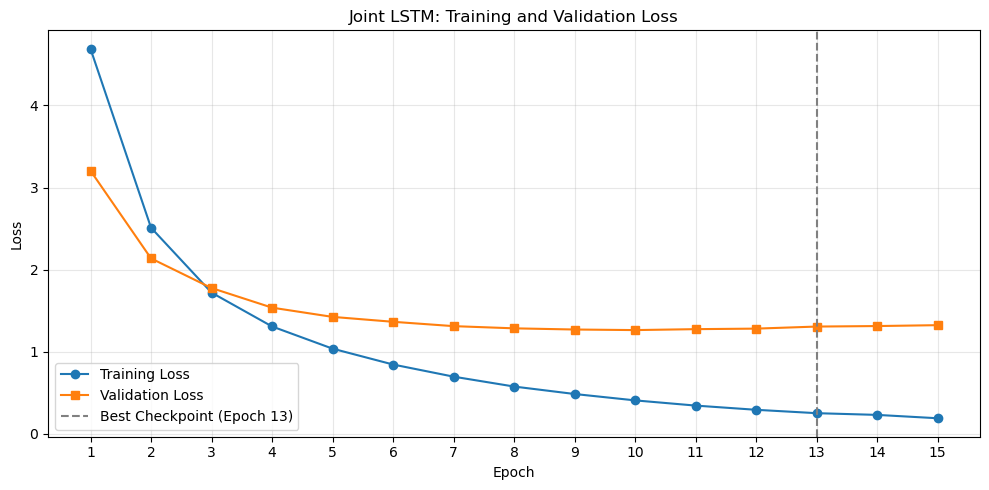

In [117]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="s",
    label="Validation Loss"
)

plt.axvline(
    x=13,
    linestyle="--",
    color="gray",
    label="Best Checkpoint (Epoch 13)"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Joint LSTM: Training and Validation Loss")
plt.xticks(history_df["epoch"])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("joint_lstm_loss_curve.png", dpi=300)
plt.show()

#### What we can interpret from above:
Epochs 1-3: The model is learning rapidly.

Both training and validation losses decrease sharply. This suggests that the model is improving on both the training data and unseen validation examples.

Epochs 4-10: The model is improving slowly

Bothe losses continue to decrease but at a slower rate

Epochs 11–15: Signs of overfitting emerge.

Training loss continues decreasing, but validation loss starts increasing slightly.

This suggests that the model is fitting the training data more closely without improving its validation loss.

#### Intent Accuracy and Slot Micro-F1

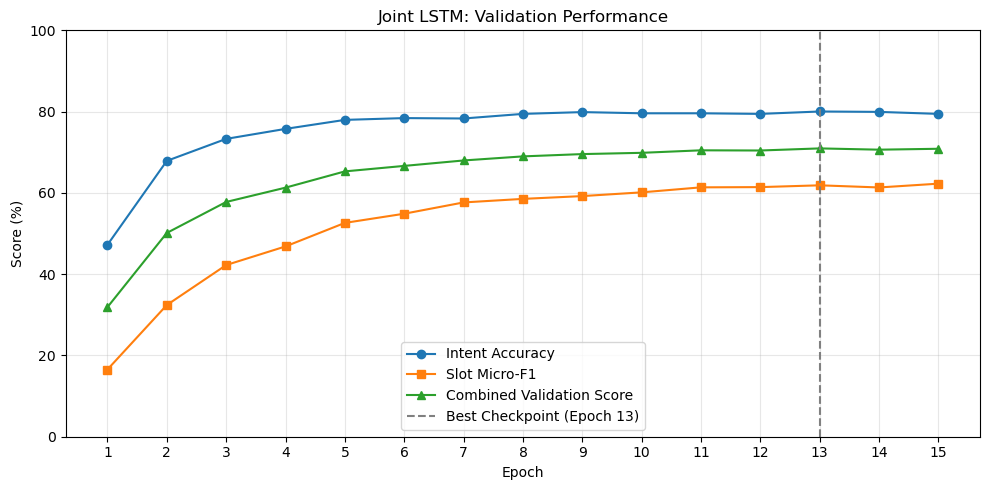

In [118]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_df["epoch"],
    history_df["intent_acc"],
    marker="o",
    label="Intent Accuracy"
)

plt.plot(
    history_df["epoch"],
    history_df["slot_f1"],
    marker="s",
    label="Slot Micro-F1"
)

plt.plot(
    history_df["epoch"],
    history_df["combined_score"],
    marker="^",
    label="Combined Validation Score"
)

plt.axvline(
    x=13,
    linestyle="--",
    color="gray",
    label="Best Checkpoint (Epoch 13)"
)

plt.xlabel("Epoch")
plt.ylabel("Score (%)")
plt.title("Joint LSTM: Validation Performance")
plt.xticks(history_df["epoch"])
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("joint_lstm_validation_metrics.png", dpi=300)
plt.show()

#### What we can interpret from above
1. Intent accurcy improves rapidly before stabilising around 79-80%

2. Slot filling improves more gradually.

Slot F1 increases from 32.40% at Epoch 2 to 62.27% at Epoch 15.

Unlike intent accuracy, slot F1 continues showing improvements later in training, although it fluctuates.

This makes sense because slot filling requires the model to identify both the correct slot type and its exact boundaries.

3. Epoch 13 remains our best checkpoint.

Although Epoch 15 achieved a higher slot F1 of 62.27%, its intent accuracy was lower.

Consequently, Epoch 13 achieved the highest combined validation score of 70.95%.

In [114]:
# adding Epoch 1 to training history

import json

# Load existing training history
with open("training_history.json", "r") as f:
    training_history = json.load(f)

# Original Epoch 1 results
epoch1_results = {
    "epoch": 1,
    "train_loss": 4.6907,
    "train_intent_loss": 3.1183,
    "train_slot_loss": 1.5724,
    "val_loss": 3.205215336754918,
    "val_intent_loss": 2.189873168244958,
    "val_slot_loss": 1.0153421680442989,
    "intent_acc": 47.22,
    "slot_f1": 16.54,
    "combined_score": 31.88,
    "tp": 200,
    "fp": 206,
    "fn": 1812,
    "elapsed_time": None
}

# Add Epoch 1 only if it is not already recorded
if not any(row["epoch"] == 1 for row in training_history):
    training_history.insert(0, epoch1_results)

# Save updated history
with open("training_history.json", "w") as f:
    json.dump(training_history, f, indent=2)

print("Recorded epochs:", [row["epoch"] for row in training_history])

Recorded epochs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
